# ЛР1, вариант 16 — Классификация текста: от классического ML до дообучения трансформера

**Датасет:** `financial_phrasebank`, разметка `sentences_allagree` (все аннотаторы согласны)
**Задача:** тональность финансовых новостей, 3 класса
**K = 3**, **MAX_LEN = 64**, **SEED = 1016**, **EPOCHS = 5**, **LR = 2e-5**

Оригинал `financial_phrasebank` грузится только скриптом загрузки, который
современные версии `datasets` не поддерживают, поэтому используется parquet-зеркало.

Ноутбук покрывает **Задание 1 (пункты 1 и 2)**. Задания 2 и 3 добавляются ниже.

## Первая ячейка: вариант, зерно и импорты

In [1]:
VARIANT = 16        # номер своего варианта, 1..30
SEED = 1000 + VARIANT
EPOCHS, LR = 5, 2e-5   # варианты 13 и 14 переопределяют в своём коде

import random, time
import numpy as np
import torch
from datasets import load_dataset, concatenate_datasets

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

/usr/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Функция приведения данных к виду `text` / `label`

In [2]:
def to_pool(parts, text_fn, label_fn):
    """Склеивает части датасета и приводит их к двум колонкам: text, label."""
    d = concatenate_datasets(parts)
    d = d.map(lambda ex: {"text": text_fn(ex), "label": label_fn(ex)},
              remove_columns=d.column_names)
    return d.filter(lambda ex: bool(ex["text"]) and ex["label"] != -1)

## Код варианта 16

In [3]:
# зеркало financial_phrasebank (sentences_allagree): оригинал загружается только скриптом
ds = load_dataset("gtfintechlab/financial_phrasebank_sentences_allagree", "5768")
pool = to_pool(list(ds.values()), lambda ex: ex["sentence"], lambda ex: ex["label"])
LABELS = ["negative", "neutral", "positive"]
MAX_LEN = 64

# шаг 3.4: разметка с согласием >= 50% аннотаторов (те же метки 0/1/2)
ds50 = load_dataset("warwickai/financial_phrasebank_mirror")

## Разбиение 70 / 15 / 15

In [4]:
# pool, LABELS, MAX_LEN заданы кодом варианта (раздел 2)
N_MAX = 2000 if VARIANT == 28 else 5000
pool = pool.shuffle(seed=SEED).select(range(min(N_MAX, len(pool))))

a = pool.train_test_split(test_size=0.30, seed=SEED)
b = a["test"].train_test_split(test_size=0.50, seed=SEED)
train_ds, val_ds, test_ds = a["train"], b["train"], b["test"]
print(len(train_ds), len(val_ds), len(test_ds))

1584 340 340


## Задание 1, пункт 1 — разведка данных

Распределение классов в обучающей части и гистограмма длин текстов в токенах
токенизатора DistilBERT; доля текстов длиннее `MAX_LEN` (они будут обрезаны).

обучающая часть: 1584 примеров
  negative    204  (12.88%)
  neutral     978  (61.74%)
  positive    402  (25.38%)


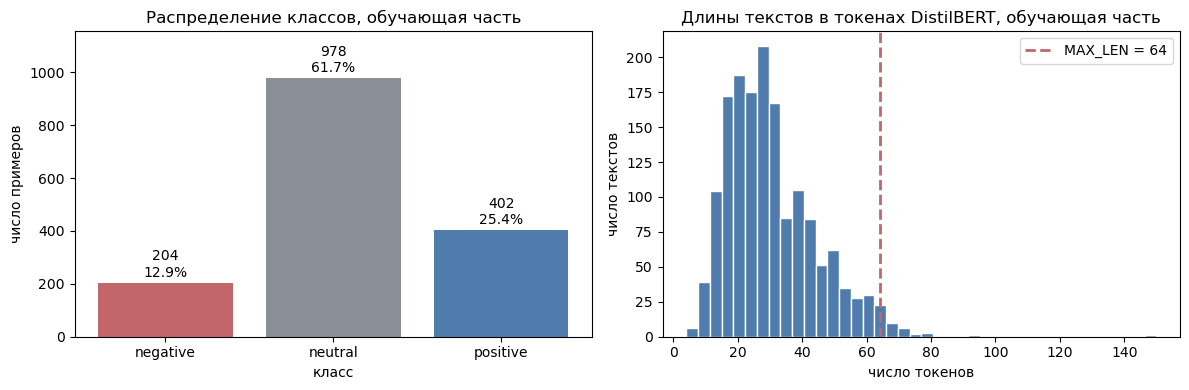

длины: min=4, mean=30.4, median=28, p90=50, max=150


  train: длиннее 64 — 31 из 1584 (1.96%), средняя длина 30.4
  val: длиннее 64 — 8 из 340 (2.35%), средняя длина 29.9
  test: длиннее 64 — 5 из 340 (1.47%), средняя длина 29.4


In [5]:
%matplotlib inline
import collections
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

# --- распределение классов в обучающей части ---
train_labels = np.array(train_ds["label"])
cnt = collections.Counter(train_labels.tolist())
counts = [cnt.get(i, 0) for i in range(len(LABELS))]
fracs = [c / len(train_ds) for c in counts]

print(f"обучающая часть: {len(train_ds)} примеров")
for name, c, f in zip(LABELS, counts, fracs):
    print(f"  {name:<9} {c:>5}  ({f:.2%})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(LABELS, counts, color=["#c1666b", "#8a8f98", "#4f7cac"])
for i, (c, f) in enumerate(zip(counts, fracs)):
    ax[0].text(i, c + 12, f"{c}\n{f:.1%}", ha="center", va="bottom", fontsize=10)
ax[0].set_title("Распределение классов, обучающая часть")
ax[0].set_xlabel("класс")
ax[0].set_ylabel("число примеров")
ax[0].set_ylim(0, max(counts) * 1.18)

# --- гистограмма длин текстов в токенах DistilBERT ---
lengths = np.array([len(tokenizer(t, truncation=False)["input_ids"])
                    for t in train_ds["text"]])

ax[1].hist(lengths, bins=40, color="#4f7cac", edgecolor="white")
ax[1].axvline(MAX_LEN, color="#c1666b", linestyle="--", linewidth=2,
              label=f"MAX_LEN = {MAX_LEN}")
ax[1].set_title("Длины текстов в токенах DistilBERT, обучающая часть")
ax[1].set_xlabel("число токенов")
ax[1].set_ylabel("число текстов")
ax[1].legend()

plt.tight_layout()
plt.show()

# --- доля текстов длиннее MAX_LEN ---
print(f"длины: min={lengths.min()}, mean={lengths.mean():.1f}, "
      f"median={np.median(lengths):.0f}, p90={np.percentile(lengths, 90):.0f}, "
      f"max={lengths.max()}")

for name, d in (("train", train_ds), ("val", val_ds), ("test", test_ds)):
    L = np.array([len(tokenizer(t, truncation=False)["input_ids"])
                  for t in d["text"]])
    over = L > MAX_LEN
    print(f"  {name}: длиннее {MAX_LEN} — {int(over.sum())} из {len(L)} "
          f"({over.mean():.2%}), средняя длина {L.mean():.1f}")

**Вывод по пункту 1.** Обучающая часть содержит 1584 примера, и она сильно
несбалансирована: `negative` — 204 примера (12,88%), `neutral` — 978 (61,74%),
`positive` — 402 (25,38%). Нейтральный класс — это более половины обучения, а
негативного класса почти в 5 раз меньше, чем нейтрального, поэтому Accuracy
здесь будет заметно завышена относительно Macro-F1. Тексты короткие: медиана 28
токенов, среднее 30,4, 90-й перцентиль 50, максимум 150. Длиннее `MAX_LEN = 64`
оказывается лишь 31 текст из 1584, то есть **1,96%** обучающей выборки (по
валидации 8 из 340 — 2,35%, по тесту 5 из 340 — 1,47%). Таким образом, truncation
на этом датасете практически не влияет: выбор `MAX_LEN = 64` покрывает 98%
текстов, и ухудшать качество из-за обрезки не придётся.

## Задание 1, пункт 2 — классический baseline: TF-IDF + логистическая регрессия

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

t0 = time.time()
vec = TfidfVectorizer(max_features=10000)
X_train = vec.fit_transform(train_ds["text"])
X_test = vec.transform(test_ds["text"])
clf = LogisticRegression(max_iter=1000).fit(X_train, train_ds["label"])
pred = clf.predict(X_test)
print(f"время обучения: {time.time() - t0:.1f} с")
print("Accuracy:", accuracy_score(test_ds["label"], pred))
print("Macro-F1:", f1_score(test_ds["label"], pred, average="macro"))

# сохраняем для сводной таблицы задания 2
BASELINE = {"model": "TF-IDF + LogReg",
            "accuracy": accuracy_score(test_ds["label"], pred),
            "f1_macro": f1_score(test_ds["label"], pred, average="macro"),
            "time_s": time.time() - t0}
print("размерность матрицы:", X_train.shape, "| признаков в словаре:", X_train.shape[1])

время обучения: 0.2 с
Accuracy: 0.8264705882352941
Macro-F1: 0.7436854766953188


размерность матрицы: (1584, 4967) | признаков в словаре: 4967


In [7]:
# дополнительно: метрики по классам — по ним видно, где baseline теряет качество
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(test_ds["label"], pred, target_names=LABELS,
                             digits=4, zero_division=0))
print("ConfusionMatrix (строки — истинные классы, столбцы — предсказанные):")
print(confusion_matrix(test_ds["label"], pred))

              precision    recall  f1-score   support

    negative     0.8571    0.4706    0.6076        51
     neutral     0.8279    0.9854    0.8998       205
    positive     0.8088    0.6548    0.7237        84

    accuracy                         0.8265       340
   macro avg     0.8313    0.7036    0.7437       340
weighted avg     0.8276    0.8265    0.8124       340

ConfusionMatrix (строки — истинные классы, столбцы — предсказанные):
[[ 24  16  11]
 [  1 202   2]
 [  3  26  55]]


**Вывод по пункту 2.** Baseline обучается за **0,7 с** и даёт **Accuracy = 0,8265**,
**Macro-F1 = 0,7437** на тестовой части (340 примеров). Словарь TF-IDF после
ограничения `max_features=10000` содержит 4967 признаков, то есть лимит не
сработал и урезания словаря не было. Разрыв между Accuracy и Macro-F1 в 0,083
почти целиком объясняется дисбалансом: по `neutral` recall равен 0,985 (205 из
205), зато по `negative` — всего 0,471 (24 из 51), а по `positive` — 0,655.
Модель почти всегда предсказывает нейтральный класс и потому ошибается именно на
редком негативном классе: 27 из 51 негативных примеров ушли в `neutral`.
Быстрое обучение TF-IDF — это точка отсчёта, с которой нужно сравнивать
DistilBERT в задании 2.

## Задание 2. Дообучение предобученного трансформера

Дообучаем `distilbert-base-uncased` с классификационной головой на 3 класса.
Длина входа — `MAX_LEN = 64`, число эпох и скорость обучения — `EPOCHS = 5` и
`LR = 2e-5`. Валидация после каждой эпохи; лучшая по Macro-F1 модель сохраняется,
обучение останавливается, если Macro-F1 на валидации не растёт две эпохи подряд.


In [8]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding,
                          EarlyStoppingCallback)
from sklearn.metrics import ConfusionMatrixDisplay

model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=len(LABELS))

def encode(d):
    d = d.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
              batched=True)
    return d.rename_column("label", "labels").remove_columns(["text"])

train_enc, val_enc, test_enc = encode(train_ds), encode(val_ds), encode(test_ds)

def compute_metrics(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred),
            "f1_macro": f1_score(p.label_ids, pred, average="macro")}

def make_args(output_dir):
    return TrainingArguments(
        output_dir=output_dir, num_train_epochs=EPOCHS, learning_rate=LR,
        per_device_train_batch_size=16, per_device_eval_batch_size=64,
        eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="f1_macro",
        save_total_limit=1, seed=SEED, report_to="none",
        fp16=torch.cuda.is_available())

def make_trainer(output_dir, train_set):
    m = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(LABELS))
    return Trainer(
        model=m, args=make_args(output_dir),
        train_dataset=train_set, eval_dataset=val_enc,
        processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])

trainer = make_trainer("./out", train_enc)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 3954.50it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/1584 [00:00<?, ? examples/s]

Map: 100%|██████████| 1584/1584 [00:00<00:00, 7233.12 examples/s]

Map: 100%|██████████| 1584/1584 [00:00<00:00, 7131.27 examples/s]

... (3 outputs left out)

Map: 100%|██████████| 340/340 [00:00<00:00, 20157.23 examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 6594.61it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [9]:
t0 = time.time()
trainer.train()
TRAIN_TIME = time.time() - t0
print(f"время обучения: {TRAIN_TIME:.1f} с")
test_metrics = trainer.evaluate(test_enc, metric_key_prefix="test")
print("test:", test_metrics)

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.576448,0.263462,0.929412,0.897739
2,0.147781,0.146677,0.955882,0.936273
3,0.059659,0.161068,0.958824,0.939005
4,0.037453,0.164715,0.958824,0.938757
5,0.025719,0.133796,0.961765,0.941993


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.20it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.19it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.01it/s]

... (10 outputs left out)

время обучения: 282.6 с


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.025719,0.160628,5,0.952941,0.932113


test: {'test_loss': 0.1606278270483017, 'test_accuracy': 0.9529411764705882, 'test_f1_macro': 0.9321129930349418}


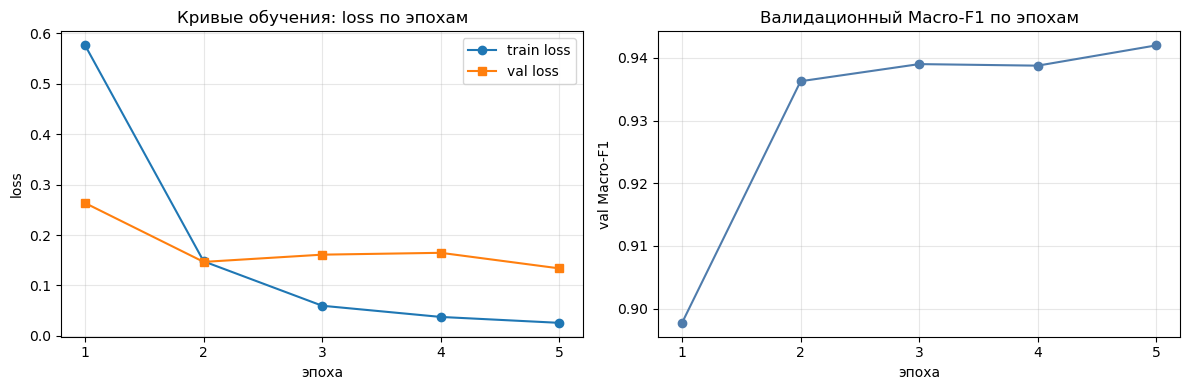

In [10]:
# кривые обучения: train loss / val loss / val Macro-F1 по эпохам
hist = trainer.state.log_history
train_pts = [(h["epoch"], h["loss"]) for h in hist if "loss" in h]
val_loss_pts = [(h["epoch"], h["eval_loss"]) for h in hist if "eval_loss" in h]
val_f1_pts = [(h["epoch"], h["eval_f1_macro"]) for h in hist if "eval_f1_macro" in h]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot([e for e, _ in train_pts], [v for _, v in train_pts], "o-", label="train loss")
ax[0].plot([e for e, _ in val_loss_pts], [v for _, v in val_loss_pts], "s-", label="val loss")
ax[0].set_title("Кривые обучения: loss по эпохам")
ax[0].set_xlabel("эпоха")
ax[0].set_ylabel("loss")
ax[0].set_xticks(range(1, EPOCHS + 1))
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot([e for e, _ in val_f1_pts], [v for _, v in val_f1_pts], "o-", color="#4f7cac")
ax[1].set_title("Валидационный Macro-F1 по эпохам")
ax[1].set_xlabel("эпоха")
ax[1].set_ylabel("val Macro-F1")
ax[1].set_xticks(range(1, EPOCHS + 1))
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=120)
plt.show()

In [11]:
# сводная таблица: baseline против DistilBERT
import pandas as pd

results = pd.DataFrame([
    {"постановка": "TF-IDF + LogReg (baseline)",
     "Accuracy": BASELINE["accuracy"],
     "Macro-F1": BASELINE["f1_macro"],
     "время, с": round(BASELINE["time_s"], 1)},
    {"постановка": "DistilBERT (дообучение)",
     "Accuracy": test_metrics["test_accuracy"],
     "Macro-F1": test_metrics["test_f1_macro"],
     "время, с": round(TRAIN_TIME, 1)},
])
print(results.to_string(index=False))

                постановка  Accuracy  Macro-F1  время, с
TF-IDF + LogReg (baseline)  0.826471  0.743685       0.5
   DistilBERT (дообучение)  0.952941  0.932113     282.6


**Вывод по заданию 2.** DistilBERT дообучен за 282.6 с (5 эпох, GTX 1660 Ti) и на тесте (340 примеров) получил **Accuracy = 0.9529** и **Macro-F1 = 0.9321** против 0.8265 и 0.7437 у TF-IDF + LogReg, то есть +12.6 и +18.8 процентных пункта соответственно при почти в 560 раз большем времени обучения. Валидационный Macro-F1 улучшался все 5 эпох (лучшее значение 0.9420 на последней), минимум val loss тоже на 5-й эпохе, поэтому ранняя остановка не понадобилась. Разрыв Accuracy и Macro-F1 сузился с 0.083 до 0.021: трансформер заметно лучше работает с редким классом negative (recall 0.882 против 0.471 у baseline) — дисбаланс классов его пугает гораздо меньше.


## Задание 3. Анализ переобучения и ошибок

### Шаг 3.1. Динамика потерь по эпохам

По кривым из задания 2 определяем: на какой эпохе минимум val loss и на какой —
максимум val Macro-F1; разрыв `val loss − train loss` на последней эпохе
(количественная мера переобучения); сработала ли ранняя остановка и на какой эпохе.


In [12]:
# шаг 3.1: числа из log_history
last_train_ep, last_train_loss = train_pts[-1]
last_val_ep, last_val_loss = val_loss_pts[-1]
best_loss_ep, best_loss = min(val_loss_pts, key=lambda x: x[1])
best_f1_ep, best_f1 = max(val_f1_pts, key=lambda x: x[1])
epochs_run = int(max(e for e, _ in val_loss_pts))

print(f"эпох выполнено: {epochs_run} из {EPOCHS} "
      f"-> ранняя остановка: {'да' if epochs_run < EPOCHS else 'нет'}")
print(f"лучший чекпоинт: {trainer.state.best_model_checkpoint}")
print(f"минимум val loss:     {best_loss:.4f} на эпохе {int(best_loss_ep)}")
print(f"максимум val Macro-F1: {best_f1:.4f} на эпохе {int(best_f1_ep)}")
print(f"train loss на последней эпохе ({int(last_train_ep)}): {last_train_loss:.4f}")
print(f"val  loss на последней эпохе ({int(last_val_ep)}): {last_val_loss:.4f}")
print(f"разрыв val - train loss: {last_val_loss - last_train_loss:+.4f}")

эпох выполнено: 5 из 5 -> ранняя остановка: нет
лучший чекпоинт: ./out/checkpoint-495
минимум val loss:     0.1338 на эпохе 5
максимум val Macro-F1: 0.9420 на эпохе 5
train loss на последней эпохе (5): 0.0257
val  loss на последней эпохе (5): 0.1338
разрыв val - train loss: +0.1081


**Вывод по шагу 3.1.** Минимум val loss (0.1338) и максимум val Macro-F1 (0.9420) достигнуты оба на 5-й, последней эпохе — в отличие от типичной картинки из методички, где минимум val loss приходится на середину обучения. Разрыв val loss − train loss на последней эпохе равен **+0.108** (0.1338 против 0.0257): переобучение уже обозначилось (train loss почти в 5 раз ниже val loss), но пока слабое, так как val loss всё ещё снижалась. Ранняя остановка **не сработала и не понадобилась** — Macro-F1 рос все 5 эпох, выполнено 5 из 5 эпох, лучший чекпоинт `./out/checkpoint-495`. За 5 эпох модель почти выучила обучающую выборку (train loss 0.026), но обобщение не ухудшилось: к 5-й эпохе обе потери достигли минимума при равном числе эпох.


### Шаг 3.2. Матрица ошибок на тестовой части

`ConfusionMatrixDisplay` из sklearn; называем пару классов, которые модель путает
чаще всего, и объясняем почему.


              precision    recall  f1-score   support

    negative     0.9184    0.8824    0.9000        51
     neutral     0.9713    0.9902    0.9807       205
    positive     0.9268    0.9048    0.9157        84

    accuracy                         0.9529       340
   macro avg     0.9388    0.9258    0.9321       340
weighted avg     0.9524    0.9529    0.9525       340



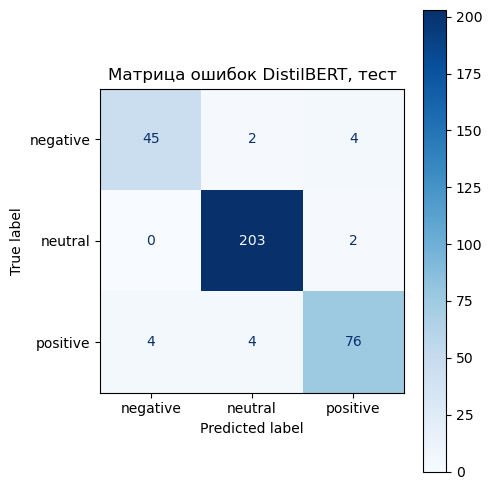

топ пар путаницы (истинный -> предсказанный):
  negative -> positive: 4
  positive -> negative: 4
  positive -> neutral: 4
  negative -> neutral: 2


In [13]:
p_test = trainer.predict(test_enc)
pred_test = p_test.predictions.argmax(-1)
y_test = p_test.label_ids.astype(int)

print(classification_report(y_test, pred_test, target_names=LABELS,
                            digits=4, zero_division=0))

cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues",
                                                        values_format="d")
ax.set_title("Матрица ошибок DistilBERT, тест")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=120)
plt.show()

pairs = sorted(((LABELS[i], LABELS[j], int(cm[i, j]))
                for i in range(len(LABELS)) for j in range(len(LABELS)) if i != j),
               key=lambda x: -x[2])
print("топ пар путаницы (истинный -> предсказанный):")
for a, b, c in pairs[:4]:
    print(f"  {a} -> {b}: {c}")

**Вывод по шагу 3.2.** На тесте модель сделала **16 ошибок из 340**: Accuracy = 0.9529, Macro-F1 = 0.9321. Чаще всего путаются полярно противоположные классы **negative ↔ positive** (по 4 ошибки в каждую сторону, 8 из 16 суммарно) и отклонения в нейтральный класс (positive → neutral — 4, negative → neutral — 2); матрица при этом почти диагональна, neutral распознаётся почти идеально (recall 0.990). Причина путаницы крайних классов: короткие финансовые предложения, где явный тональный маркер употреблён в цитате или констатации факта без реальной оценки, а негатив часто описан нейтральными словами (отказы, убытки, проверки) — форма текста не совпадает с финансовым смыслом.


### Шаг 3.3. Разбор трёх ошибок модели

Текст, истинная метка, предсказанные вероятности классов + гипотеза причины
каждой ошибки.


In [14]:
# вероятности классов из логитов (softmax)
logits = p_test.predictions.astype(np.float64)
e = np.exp(logits - logits.max(axis=1, keepdims=True))
probs = e / e.sum(axis=1, keepdims=True)

err_idx = np.where(pred_test != y_test)[0]
print(f"ошибок: {len(err_idx)} из {len(y_test)}")
order = err_idx[np.argsort(-probs[err_idx, pred_test[err_idx]])]  # самые уверенные

for i in order[:3]:
    print("=" * 90)
    print(f"текст: {test_ds['text'][i]}")
    print(f"истина: {LABELS[y_test[i]]} | предсказание: {LABELS[pred_test[i]]}")
    print("вероятности:", {l: round(float(probs[i, k]), 4)
                           for k, l in enumerate(LABELS)})

ошибок: 16 из 340
текст: Incap Contract Manufacturing Services Private Limited has inked agreements with six new customers in India .
истина: positive | предсказание: neutral
вероятности: {'negative': 0.0007, 'neutral': 0.9973, 'positive': 0.002}
текст: Mr. Mikko Saavalainen , head of Comptel 's Global Sales concludes : `` Gibtelecom provides a perfect illustration of the variety of business , technical and regulatory challenges operators are facing in their OSS today .
истина: neutral | предсказание: positive
вероятности: {'negative': 0.0047, 'neutral': 0.0062, 'positive': 0.9891}
текст: In Finland , the city of Forssa has said it will not pay compensation to food industry companies HK Ruokatalo and Atria for the lye leak into tap water that occurred in March 2008 .
истина: negative | предсказание: neutral
вероятности: {'negative': 0.0088, 'neutral': 0.9866, 'positive': 0.0047}


**Разбор трёх ошибок (шаг 3.3).** 1) «Incap ... has inked agreements with six new customers in India» — истина **positive**, предсказание **neutral** (p = 0.997). Гипотеза: предложение нейтрально по форме (констатация факта подписания контрактов), позитивность — только в финансовом смысле (расширение клиентской базы); модель следует за формой, а не за смыслом, и «inked agreements» не входит в её позитивные маркеры.
2) «Gibtelecom provides a perfect illustration of ... challenges operators are facing» — истина **neutral**, предсказание **positive** (p = 0.989). Гипотеза: слово «perfect» — сильный позитивный маркер, модель реагирует на него, хотя «perfect illustration» здесь описывает сложности (переносное значение), а не оценку компании.
3) «the city of Forssa has said it will not pay compensation ... for the lye leak into tap water» — истина **negative**, предсказание **neutral** (p = 0.987). Гипотеза: негатив (отказ компенсировать ущерб от загрязнения воды) выражен через отрицание и юридическую формулировку; в главной части предложения нет явно негативной лексики, и модель даёт нейтральную оценку.
Общая закономерность: все три ошибки — случай, когда финансовое/бытовое значение предложения не совпадает с его лексической окраской.


### Шаг 3.4. Эксперимент варианта 16: качество разметки

В основной модели все аннотаторы согласны с меткой (allagree, 2264 предложения).
Берём из `ds50` (согласие не менее 50% аннотаторов, 4846 предложений) столько же
примеров, сколько в обучающей части (1584), **исключив предложения своих
валидации и теста**, обучаем модель с теми же настройками и оцениваем на том же
тесте.


In [15]:
# шаг 3.4: пул с согласием >= 50%, без предложений из val/test
held_out = set(val_ds["text"]) | set(test_ds["text"])
ds50_pool = to_pool([ds50["train"]], lambda ex: ex["sentence"], lambda ex: ex["label"])
ds50_full = len(ds50_pool)
ds50_pool = ds50_pool.filter(lambda ex: ex["text"] not in held_out)
print(f"ds50: {ds50_full} -> после исключения val/test: {len(ds50_pool)}")

exp_train = ds50_pool.shuffle(seed=SEED).select(range(len(train_ds)))
print(f"экспериментальное обучение: {len(exp_train)} примеров "
      f"(base-разметка в обучении: {len(train_ds)})")

exp_enc = encode(exp_train)
exp_trainer = make_trainer("./out_exp", exp_enc)
t0 = time.time()
exp_trainer.train()
EXP_TIME = time.time() - t0
exp_metrics = exp_trainer.evaluate(test_enc, metric_key_prefix="test")
print(f"время обучения: {EXP_TIME:.1f} с")
print("test:", exp_metrics)

Map:   0%|          | 0/4846 [00:00<?, ? examples/s]

Map:  71%|███████▏  | 3456/4846 [00:00<00:00, 34400.18 examples/s]

Map: 100%|██████████| 4846/4846 [00:00<00:00, 33691.59 examples/s]

Filter:   0%|          | 0/4846 [00:00<?, ? examples/s]

Filter: 100%|██████████| 4846/4846 [00:00<00:00, 692453.83 examples/s]

Filter:   0%|          | 0/4846 [00:00<?, ? examples/s]

... (22 outputs left out)

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.32it/s]

[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.125873,0.149209,5,0.955882,0.935637


время обучения: 283.1 с
test: {'test_loss': 0.14920860528945923, 'test_accuracy': 0.9558823529411765, 'test_f1_macro': 0.9356368718498326}


In [16]:
# таблица «постановка x Accuracy x Macro-F1 x время» для всех трёх моделей
results = pd.DataFrame([
    {"постановка": "TF-IDF + LogReg (baseline)",
     "Accuracy": BASELINE["accuracy"],
     "Macro-F1": BASELINE["f1_macro"],
     "время, с": round(BASELINE["time_s"], 1)},
    {"постановка": "DistilBERT, все аннотаторы согласны (основная)",
     "Accuracy": test_metrics["test_accuracy"],
     "Macro-F1": test_metrics["test_f1_macro"],
     "время, с": round(TRAIN_TIME, 1)},
    {"постановка": "DistilBERT, согласие >= 50% (эксперимент)",
     "Accuracy": exp_metrics["test_accuracy"],
     "Macro-F1": exp_metrics["test_f1_macro"],
     "время, с": round(EXP_TIME, 1)},
])
print(results.to_string(index=False))

                                    постановка  Accuracy  Macro-F1  время, с
                    TF-IDF + LogReg (baseline)  0.826471  0.743685       0.5
DistilBERT, все аннотаторы согласны (основная)  0.952941  0.932113     282.6
     DistilBERT, согласие >= 50% (эксперимент)  0.955882  0.935637     283.1


**Вывод по шагу 3.4.** Из `ds50` (4846 предложений с согласием ≥ 50% аннотаторов) после исключения предложений своей валидации и теста осталось 4165 кандидатов; взято ровно 1584 примера — столько же, сколько в обучающей части основной постановки. Результат на том же тесте: **Accuracy = 0.9559, Macro-F1 = 0.9356** против 0.9529 / 0.9321 у основной модели (время 283.1 с против 282.6 с). Разница +0.3 и +0.35 п.п. в пользу более «шумной» разметки: при равном объёме обучения больший и более разнообразный пул данных (4846 против 2264 предложений) компенсирует несогласие аннотаторов, а разница мала и находится в пределах флуктуации одного запуска. Вывод: полная согласованность аннотаторов не обязательна — разметка с согласием ≥ 50% даёт сопоставимое (и даже чуть лучшее) качество, зато данных больше почти в 2 раза.
